<a href="https://colab.research.google.com/github/akshu88/Applied-ML-Lab/blob/main/Exp_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



---

**IMPORT LIBRARIES**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

**Load the dataset and analyse the data**


In [ ]:
df = pd.read_csv("indian_engineering_placement_2026.csv")

print(df.sample(10))

      Student_ID  Age  Gender           State      Branch College_Tier  CGPA  \
8043     ST08044   21  Female     Uttarakhand  Mechanical       Tier-2  6.19   
2931     ST02932   20    Male         Haryana         ECE       Tier-2  7.08   
7233     ST07234   21    Male         Gujarat  Mechanical       Tier-1  8.51   
13920    ST13921   22    Male  Andhra Pradesh         CSE       Tier-2  8.12   
4196     ST04197   19    Male       Karnataka        AIML       Tier-3  7.01   
12769    ST12770   20    Male          Kerala        AIML       Tier-2  6.35   
2957     ST02958   18  Female      Tamil Nadu          IT       Tier-2  8.96   
1920     ST01921   21    Male           Delhi          IT       Tier-1  7.52   
1419     ST01420   25    Male      Tamil Nadu          IT       Tier-3  8.89   
5840     ST05841   21    Male  Andhra Pradesh       Civil       Tier-3  8.06   

       Attendance_Percentage  DSA_Problems_Solved  Aptitude_Score  ...  \
8043                   70.64                 

In [ ]:
print(df.shape)

(15000, 25)


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      15000 non-null  object 
 1   Age                             15000 non-null  int64  
 2   Gender                          15000 non-null  object 
 3   State                           15000 non-null  object 
 4   Branch                          15000 non-null  object 
 5   College_Tier                    15000 non-null  object 
 6   CGPA                            15000 non-null  float64
 7   Attendance_Percentage           15000 non-null  float64
 8   DSA_Problems_Solved             15000 non-null  int64  
 9   Aptitude_Score                  15000 non-null  int64  
 10  Communication_Score             15000 non-null  int64  
 11  Projects_Count                  15000 non-null  int64  
 12  Internships_Count               

In [ ]:
print(df.describe())

                Age          CGPA  Attendance_Percentage  DSA_Problems_Solved  \
count  15000.000000  15000.000000           15000.000000         15000.000000   
mean      21.153400      7.477432              73.774239           181.760667   
std        1.536324      0.870838               7.516522            83.611775   
min       18.000000      4.050000              50.000000            12.000000   
25%       20.000000      6.890000              68.660000           123.000000   
50%       21.000000      7.470000              73.720000           176.000000   
75%       22.000000      8.060000              78.810000           225.000000   
max       25.000000     10.000000             100.000000          1199.000000   

       Aptitude_Score  Communication_Score  Projects_Count  Internships_Count  \
count    15000.000000         15000.000000    15000.000000       15000.000000   
mean        39.993400            53.912333        3.514600           1.201267   
std         14.400763      

In [ ]:
print('Missing values before cleaning:')
print(df.isnull().sum())

df["Open_Source_Contributions"] = pd.to_numeric(df["Open_Source_Contributions"], errors='coerce')
median_open_source = df["Open_Source_Contributions"].median()
df["Open_Source_Contributions"] = df["Open_Source_Contributions"].fillna(median_open_source)

df["LinkedIn_Activity_Score"] = pd.to_numeric(df["LinkedIn_Activity_Score"], errors='coerce')
mean_linkedin_activity = df["LinkedIn_Activity_Score"].mean()
df["LinkedIn_Activity_Score"] = df["LinkedIn_Activity_Score"].fillna(mean_linkedin_activity)

print('\nMissing values after filling:')
print(df.isnull().sum())

print('\nNumber of duplicate rows before dropping:')
print(df.duplicated().sum())

df = df.drop_duplicates()

print('Number of duplicate rows after dropping:')
print(df.duplicated().sum())

Missing values before cleaning:
Student_ID                          0
Age                                 0
Gender                              0
State                               0
Branch                              0
College_Tier                        0
CGPA                                0
Attendance_Percentage               0
DSA_Problems_Solved                 0
Aptitude_Score                      0
Communication_Score                 0
Projects_Count                      0
Internships_Count                   0
Certifications_Count                0
Open_Source_Contributions         255
GitHub_Contributions                0
LinkedIn_Activity_Score           225
Hackathons_Participated             0
Competitive_Programming_Rating      0
Study_Hours_Per_Week                0
Soft_Skills_Score                   0
Leadership_Experience               0
Extracurricular_Activities          0
Placement_Status                    0
Package_LPA                         0
dtype: int64

Miss

In [ ]:
print(df.duplicated().sum())

0


In [ ]:
median = df["Open_Source_Contributions"].quantile(0.50)
df["Open_Source_Contributions"] = df["Open_Source_Contributions"].fillna(median)

mean = df["LinkedIn_Activity_Score"].mean
df["LinkedIn_Activity_Score"] = df["LinkedIn_Activity_Score"].fillna(mean)

df = df.drop_duplicates()

**Visualize the data**

In [ ]:
numerical_col = df.select_dtypes(include=['float64', 'int64'])


<Axes: ylabel='Study_Hours_Per_Week'>

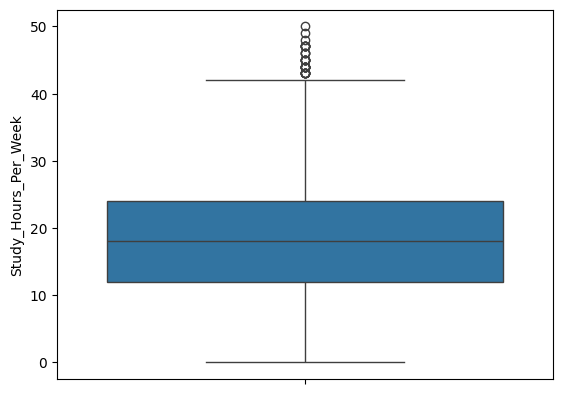

In [ ]:

sns.boxplot(df["Study_Hours_Per_Week"])

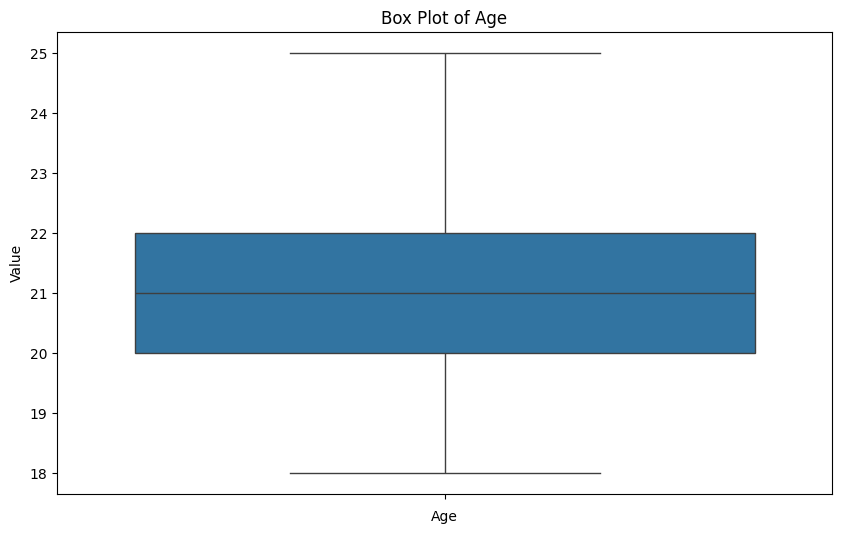

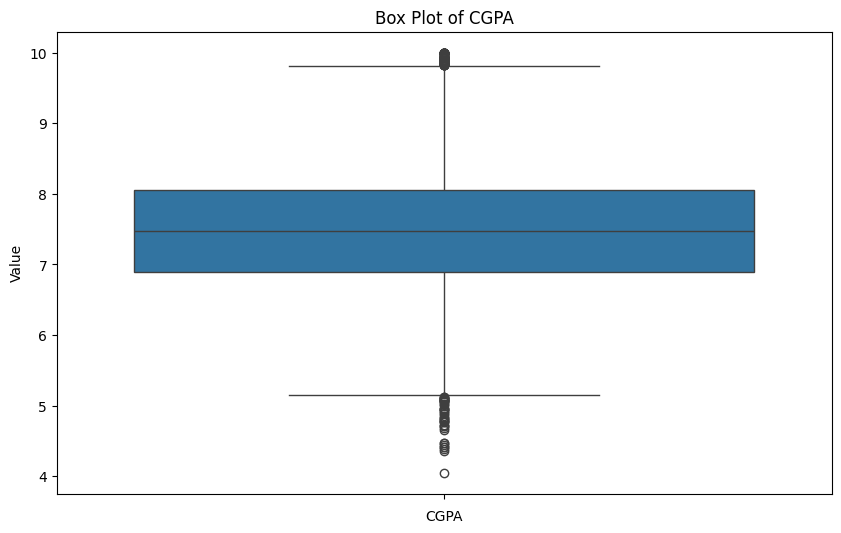

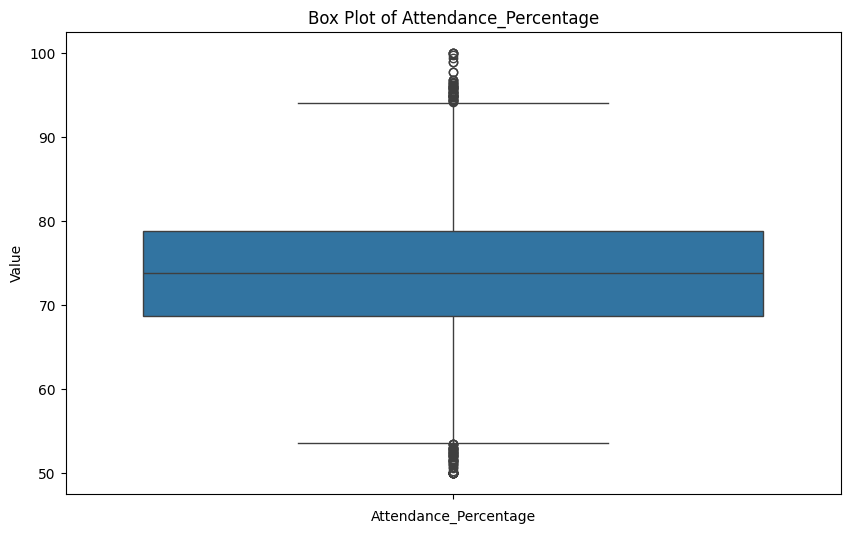

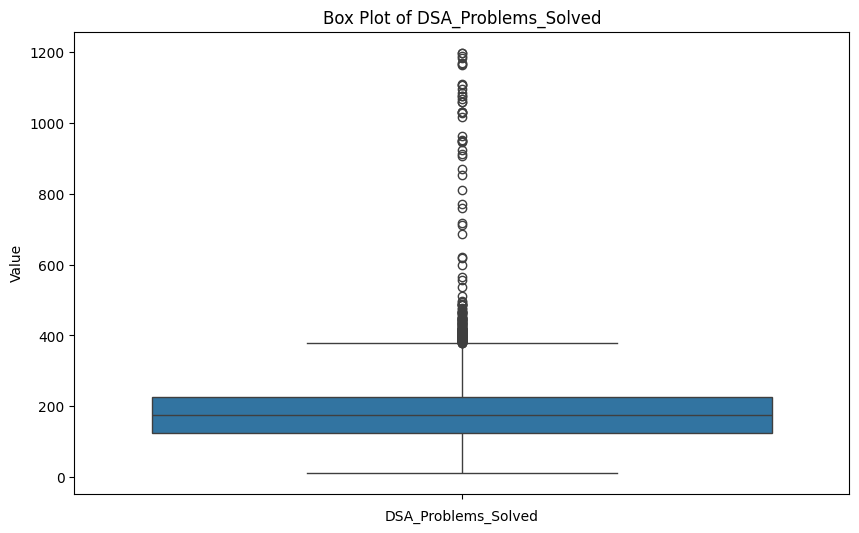

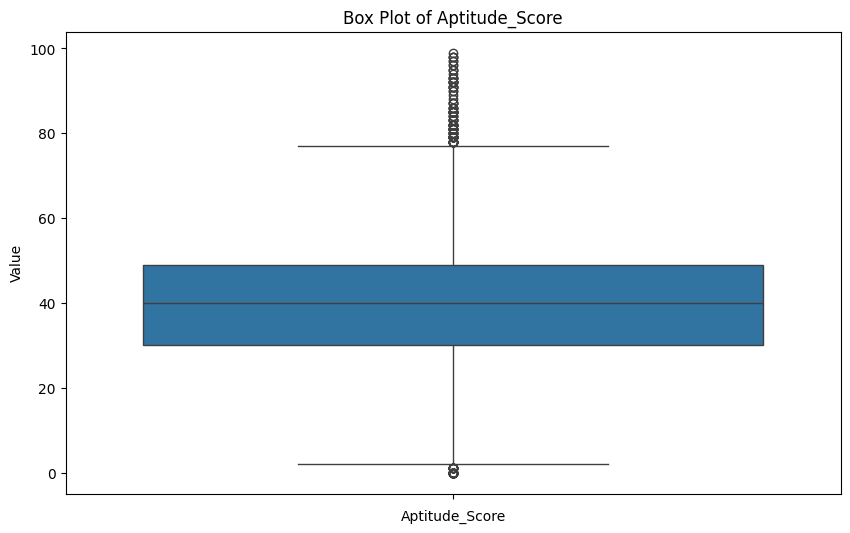

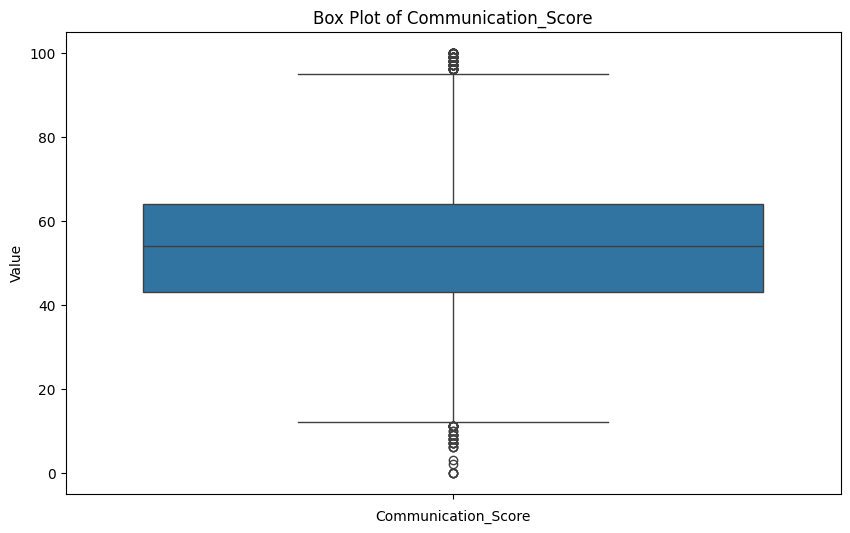

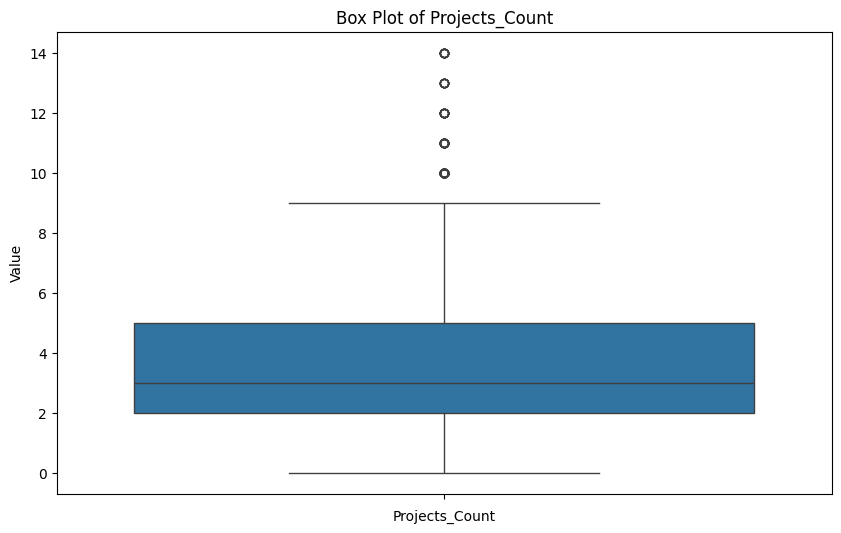

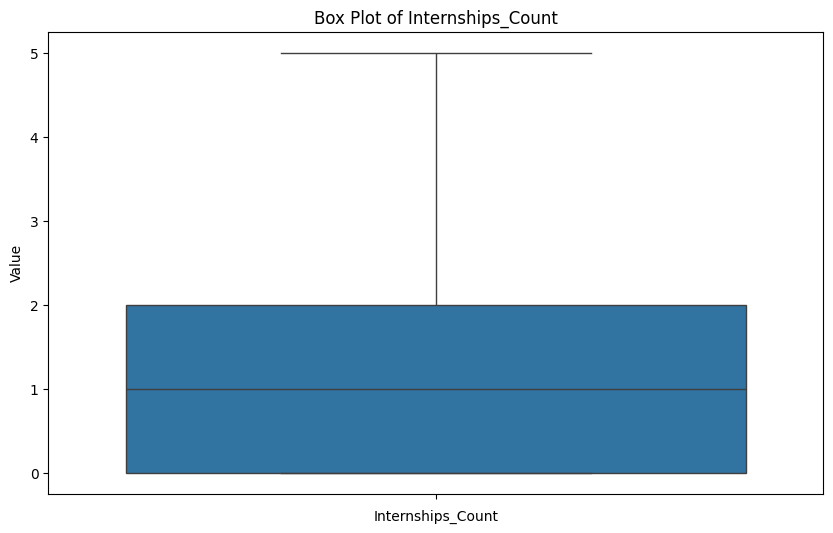

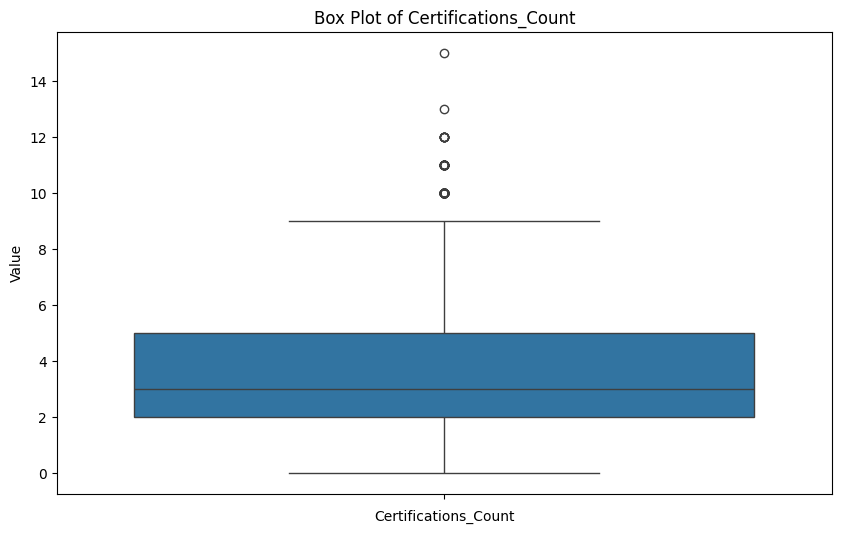

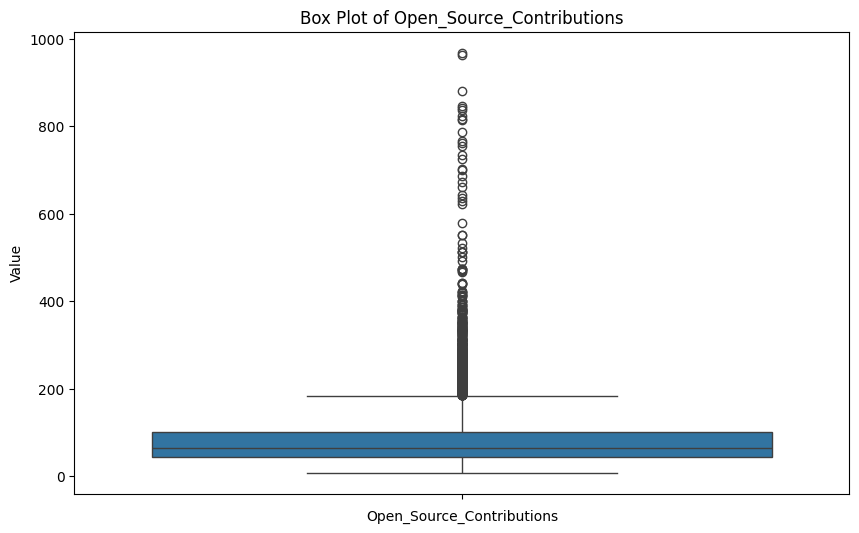

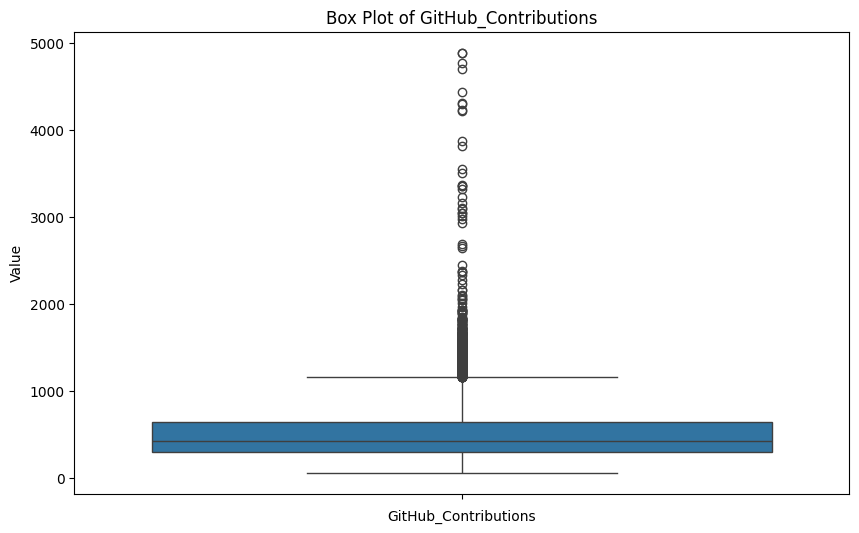

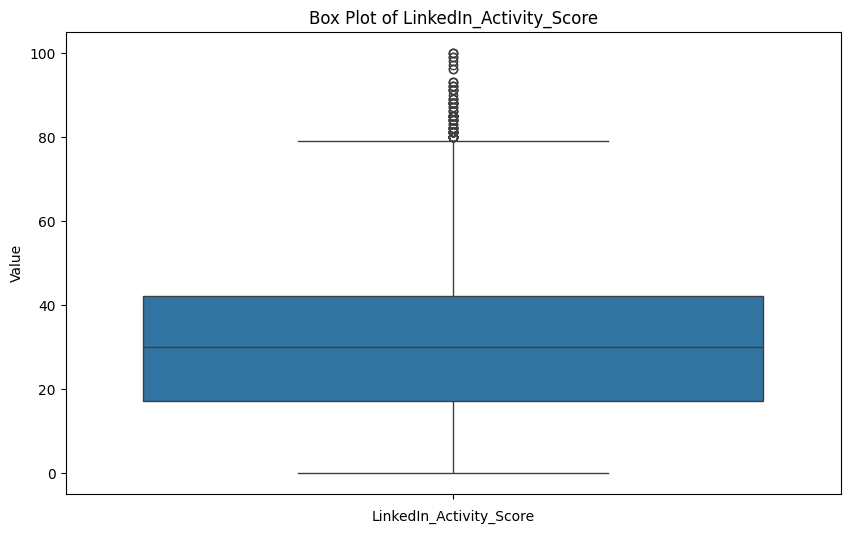

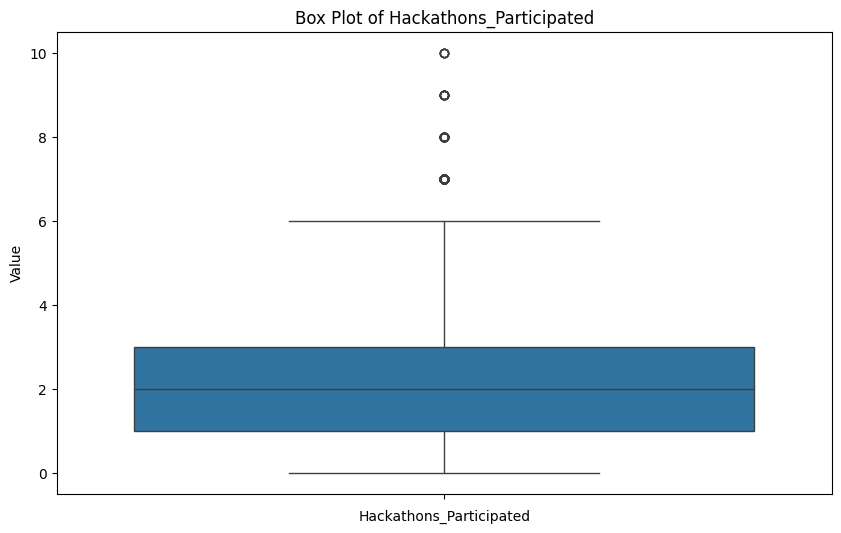

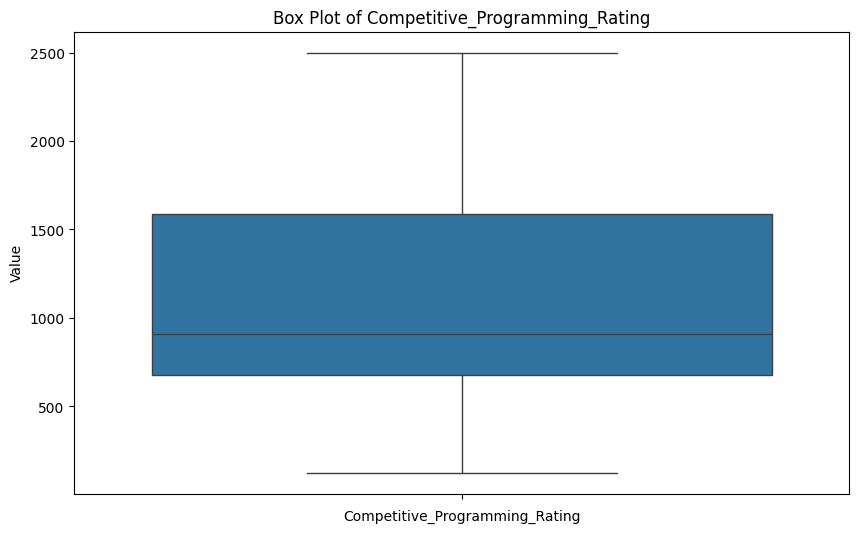

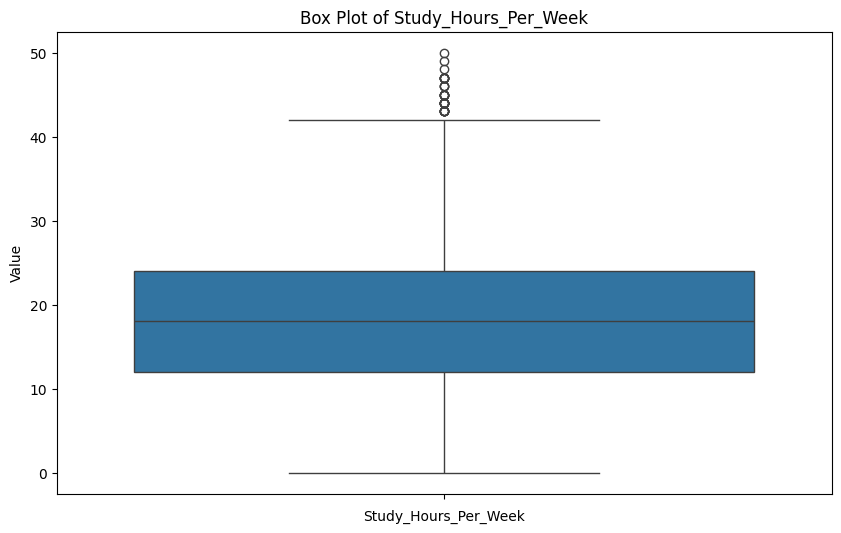

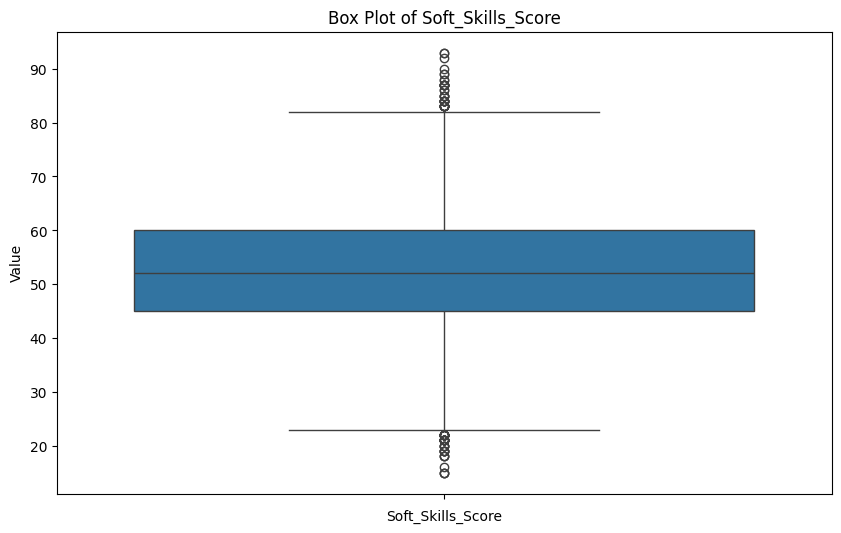

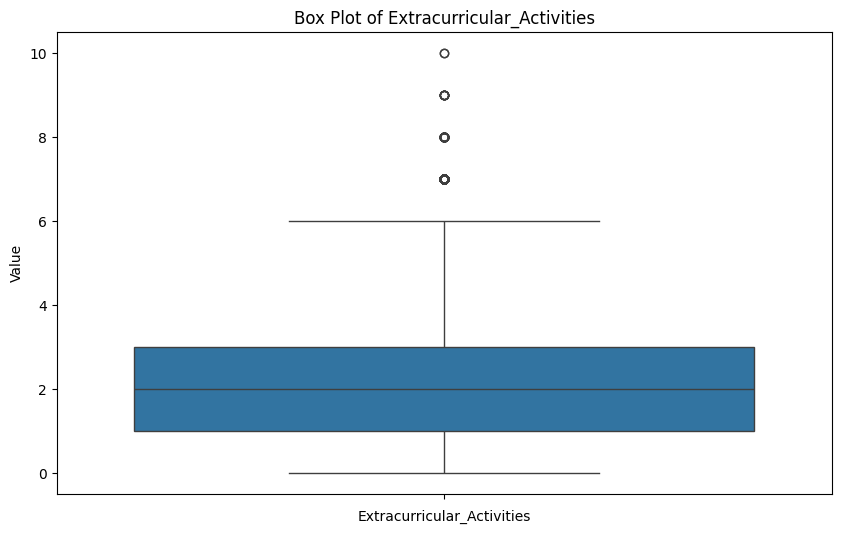

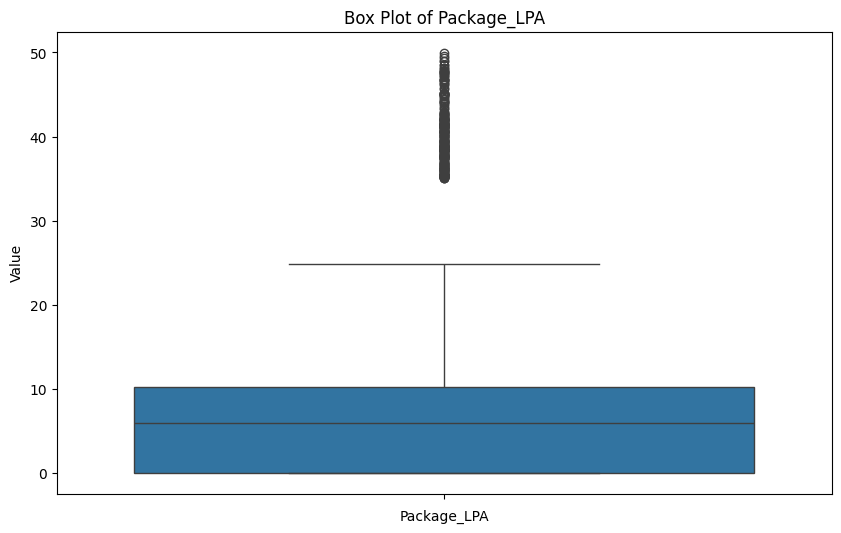

In [ ]:
for col in numerical_col:
    plt.figure(figsize=(10, 6))
    sns.boxplot(df[col])
    plt.title(f'Box Plot of {col}')
    plt.xlabel(col)
    plt.ylabel('Value')
    plt.show()

**Handling Outliers**

In [ ]:
q1 = df["Age"].quantile(0.25)
q3 = df["Age"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outilers = df[(df["Age"] < lower_bound) | (df["Age"] > upper_bound)]
print(outilers)

df["Age"] = df["Age"].clip(lower_bound, upper_bound)

Empty DataFrame
Columns: [Student_ID, Age, Gender, State, Branch, College_Tier, CGPA, Attendance_Percentage, DSA_Problems_Solved, Aptitude_Score, Communication_Score, Projects_Count, Internships_Count, Certifications_Count, Open_Source_Contributions, GitHub_Contributions, LinkedIn_Activity_Score, Hackathons_Participated, Competitive_Programming_Rating, Study_Hours_Per_Week, Soft_Skills_Score, Leadership_Experience, Extracurricular_Activities, Placement_Status, Package_LPA]
Index: []

[0 rows x 25 columns]


In [ ]:
# df = df.drop("Student_ID", axis = 1)
df = df.drop(columns=["Student_ID", "Placement_Status"], errors="ignore")
# df = df.drop("Placement_Status",axis = 1)

Train test split

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("Package_LPA", axis=1)
y = df["Package_LPA"]

print(X)
X_train, X_test, y_train, y_test = train_test_split (X,y, test_size=0.2, random_state=42)

       Age  Gender          State      Branch College_Tier  CGPA  \
0       22    Male     Tamil Nadu  Mechanical       Tier-3  6.25   
1       21    Male  Uttar Pradesh  Mechanical       Tier-3  7.53   
2       23    Male      Jharkhand          IT       Tier-3  7.90   
3       22  Female    Maharashtra         CSE       Tier-3  7.00   
4       19    Male    Maharashtra        AIML       Tier-2  6.23   
...    ...     ...            ...         ...          ...   ...   
14995   23  Female      Karnataka         CSE       Tier-1  7.35   
14996   21    Male        Haryana        AIML       Tier-3  6.77   
14997   19    Male          Delhi         CSE       Tier-2  8.09   
14998   20  Female    Maharashtra          IT       Tier-2  6.75   
14999   23    Male    Maharashtra         CSE       Tier-2  7.54   

       Attendance_Percentage  DSA_Problems_Solved  Aptitude_Score  \
0                      67.07                   54              25   
1                      87.69                 

**Apply Feature Scaling**

**1. Filter based**

Correlation based variance based


In [ ]:
corr = df.corr(numeric_only=True)

corr

,Age,CGPA,Attendance_Percentage,DSA_Problems_Solved,Aptitude_Score,Communication_Score,Projects_Count,Internships_Count,Certifications_Count,Open_Source_Contributions,GitHub_Contributions,LinkedIn_Activity_Score,Hackathons_Participated,Competitive_Programming_Rating,Study_Hours_Per_Week,Soft_Skills_Score,Extracurricular_Activities,Package_LPA
Age,1.000000,-0.010336,-0.001145,0.003533,0.007281,-0.002677,0.007120,0.007701,-0.002814,0.003384,0.002772,-0.004143,0.004908,0.006888,0.001176,-0.001414,-0.017772,0.002745
CGPA,-0.010336,1.000000,0.357878,0.340988,0.388994,0.074100,0.227861,0.187248,0.207905,0.145019,0.152979,0.012131,0.096357,0.149763,0.342682,0.046450,0.005188,0.330195
Attendance_Percentage,-0.001145,0.357878,1.000000,0.089616,0.132595,0.017235,0.080861,0.061948,0.079271,0.024337,0.037917,0.003456,0.032719,0.045013,0.133973,0.015416,0.003622,0.107772
DSA_Problems_Solved,0.003533,0.340988,0.089616,1.000000,0.179648,0.166968,0.296272,0.207673,0.211152,0.609160,0.652124,0.038331,0.181779,0.728414,0.096388,0.090942,0.017412,0.627133
Aptitude_Score,0.007281,0.388994,0.132595,0.179648,1.000000,0.048693,0.109133,0.096517,0.080519,0.104335,0.106667,0.005572,0.029840,0.051853,0.122234,0.020321,0.008232,0.181072
Communication_Score,-0.002677,0.074100,0.017235,0.166968,0.048693,1.000000,0.048165,0.072495,0.024545,0.084689,0.083451,0.386260,0.003958,0.066984,0.018299,0.832283,0.003319,0.204367
Projects_Count,0.007120,0.227861,0.080861,0.296272,0.109133,0.048165,1.000000,0.093234,0.122990,0.227423,0.251766,-0.001816,0.095528,0.269240,0.067978,0.024777,0.008052,0.309873
Internships_Count,0.007701,0.187248,0.061948,0.207673,0.096517,0.072495,0.093234,1.000000,0.075908,0.129148,0.135577,0.026215,0.046382,0.154957,0.072848,0.052030,0.002456,0.326769
Certifications_Count,-0.002814,0.207905,0.079271,0.211152,0.080519,0.024545,0.122990,0.075908,1.000000,0.176620,0.194658,0.002766,0.104155,0.290985,0.074453,0.025141,0.028550,0.185551
Open_Source_Contributions,0.003384,0.145019,0.024337,0.609160,0.104335,0.084689,0.227423,0.129148,0.176620,1.000000,0.696652,0.003569,0.154414,0.560504,0.039937,0.022831,0.016181,0.511289


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

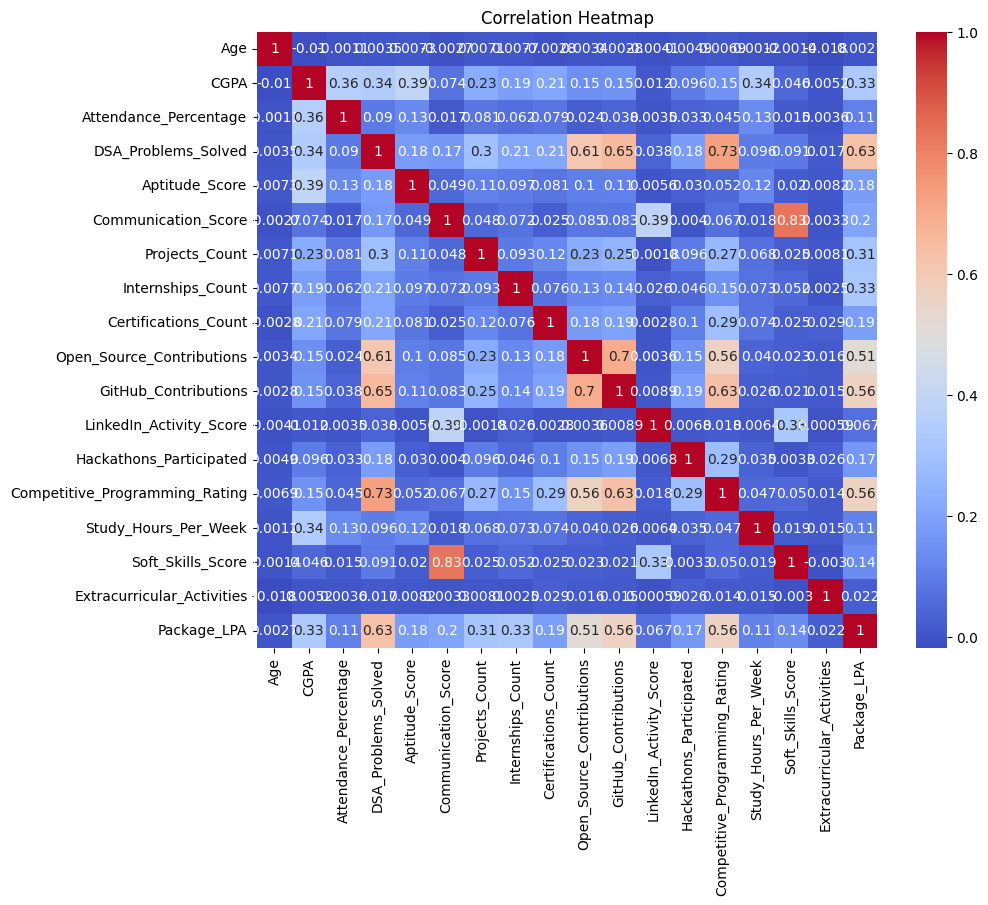

In [ ]:
fig = plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt

# **Correlation with label**

In [ ]:
corr = df.corr(numeric_only=True)
corr_with_label = corr["Package_LPA"].sort_values(ascending=False)
print(corr_with_label)

Package_LPA                       1.000000
DSA_Problems_Solved               0.627133
Competitive_Programming_Rating    0.564983
GitHub_Contributions              0.561650
Open_Source_Contributions         0.511289
CGPA                              0.330195
Internships_Count                 0.326769
Projects_Count                    0.309873
Communication_Score               0.204367
Certifications_Count              0.185551
Aptitude_Score                    0.181072
Hackathons_Participated           0.168321
Soft_Skills_Score                 0.139597
Study_Hours_Per_Week              0.109882
Attendance_Percentage             0.107772
LinkedIn_Activity_Score           0.067193
Extracurricular_Activities        0.022488
Age                               0.002745
Name: Package_LPA, dtype: float64


In [ ]:
corr = df.corr(numeric_only=True)["Package_LPA"]
selected_features = corr[corr.abs() >= 0.1].index
df = df[selected_features]
print(df.columns)

Index(['CGPA', 'Attendance_Percentage', 'DSA_Problems_Solved',
       'Aptitude_Score', 'Communication_Score', 'Projects_Count',
       'Internships_Count', 'Certifications_Count',
       'Open_Source_Contributions', 'GitHub_Contributions',
       'Hackathons_Participated', 'Competitive_Programming_Rating',
       'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Package_LPA'],
      dtype='object')


**By interpreting the above shown heatmap of correlation, three features are adding very less value to our target label i.e. Package_LPA**

**Logistic Regression**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score

X = df.drop('Package_LPA', axis=1)
y = df['Package_LPA']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", root_mean_squared_error(y_test, y_pred))

R2 Score: 0.530851463656379
RMSE: 4.99303174169395
